# MLOps: data contracts, CI gates and monitoring

This worked reference is validated on CPU. Accelerator compatibility requires a separate source review and target execution receipt. Use the execution matrix to review device selection and data ownership before adapting a separate target program.

- Validate data before training
- Evaluate predictions from a reloaded local artifact
- Keep group-safe splits and count-weighted slice metrics
- Separate code CI from model delivery
- Interpret distribution change without inventing labels

A candidate looks good on an average dashboard, yet performs badly for a small group of requests. Train and reload a tiny local artifact, compute predictions against a fixed evaluation set, then make the release decision from per-example and count-weighted slice metrics.

## The idea

A release pipeline connects data contracts, evaluation and artifact selection. This offline experiment serializes model parameters, reloads them as a consumer would, and derives every error from observed predictions and targets. Aggregate metrics summarize behavior, while required slices carry explicit gates and counts.

## A passing average can hide a failing slice

Start with $10$ held-out requests: $9$ low-input rows and $1$ high-input row. For candidate A, each low row has squared error $0.01$, while the one high row has squared error $4$. The low errors contribute $9 \times 0.01 = 0.09$; adding $4$ and dividing by $10$ gives overall MSE $0.409$. That average looks under the illustrative $0.5$ limit, but the high-input row still fails its required slice gate. The decision needs both the aggregate and the slice policy.

The plot compares those same rows after reloading candidate A and candidate B. Counts tell you what each mean summarizes: $9$ low examples, $1$ high example, $10$ overall. A count of $1$ is a useful warning about how little evidence the high-slice mean represents. Monitoring later asks a different question: whether the input mix changed.

### Pause and reason

Why define a slice gate before inspecting candidate results?

<details><summary>Compare your reasoning</summary>

It makes the selection rule explicit and reduces post-hoc cherry-picking. The gate should reflect the application's requirements, with sample counts and uncertainty considered.

</details>

## Validate data before the expensive job

Before training, inspect each row as a record with an ID, source group, split, numeric inputs and target, and declared slice. The fixture checks that the fields are known, numbers are finite, split and slice names are allowed, IDs are unique, and every source group stays in one split. A new row ID does not prevent leakage: if two rows came from the same subject but one is in train and one is in test, the model can indirectly see the held-out source during training. Reject that manifest before spending time on a job. Hashing the accepted rows gives later stages a way to identify which data was checked. In a feature pipeline, record event time, transformation version and missing-value rules so a changed serving input can be traced.

## Use a fixed release evaluation

The consumer reads candidate A back from its serialized file, predicts each held-out row, and squares prediction minus target. For low row low-0, prediction $1.0$ against target $1.1$ gives $(1.0 - 1.1)^2 = 0.01$. The $9$ low rows each have that error, so their mean is $0.01$. For high-0, prediction $17.0$ against target $19.0$ gives $4.0$; because it is the only high row, its slice MSE is $4.0$. The overall mean is the count-weighted sum, $\frac{9 \times 0.01 + 1 \times 4.0}{10} = 0.409$.

Candidate B is separately saved and reloaded. Its high-slice offset changes the prediction for high-0 to $18.9$, making that row's squared error $0.01$. On the same $10$ IDs, labels and policy, all three means are $0.01$ and all gates pass. This comparison changes the candidate while keeping the evaluation fixed; the later label-correction check asks a different question.

$$
\operatorname{MSE}_{\mathrm{all}}=\frac{\sum_s n_s\operatorname{MSE}_s}{\sum_s n_s}
$$

## Separate code CI from model delivery

Treat code CI and model delivery as connected stages with different evidence. Code CI checks the pipeline source, schema handling and numerical behavior. Model delivery then identifies a candidate, evaluates it on a frozen versioned set, packages the serving artifact and checks that package before promotion. A passing code test cannot certify a particular model's slice metrics, and a passing model evaluation cannot show that the next code change is safe. The example workflow isolates its MLflow SQLite store per job and its container step does not publish an image. A team should retain run metadata and artifacts outside temporary workers, and promote a recorded model/image pair only after both kinds of checks pass.

## Compare distributions without inventing labels

Here the two-bin input mix moves from $90\%$ low and $10\%$ high to $50\%$ low and $50\%$ high. Total variation is half the sum of the bin changes: $\frac{1}{2}(\lvert 0.9 - 0.5\rvert + \lvert 0.1 - 0.5\rvert) = 0.4$. This describes a substantial change under these declared bins; it says nothing directly about correctness because no new outcome labels are part of this calculation. First ask whether the change reflects a broken feature pipeline or a legitimate population shift. Keep distribution counts alongside delayed-label slice outcomes and service measures such as latency, so the next action follows the evidence available.

$$
\operatorname{TV}(p,q)=\tfrac12\sum_b|p_b-q_b|
$$

## Plan a response instead of a reflex

Give the alert a named owner, a time window and a runbook step. If the high-input share rises, check schema and preprocessing first, then identify which requests changed and whether labels have arrived. A malformed-input spike may call for quarantine; a valid new population calls for collecting outcomes and comparing a candidate on an appropriate evaluation set. Consider rollback only if serving evidence or a valid comparison supports it. Retraining on corrupted inputs can encode the problem into a new model. Record sample counts with the alert because a short, small window can make an ordinary fluctuation look decisive.

## Rehearse the failed gate

Walk the release evidence in order. The manifest validator accepts the separated groups, then the consumer reloads two distinct artifacts and evaluates the same $10$ held-out IDs. Candidate A records low MSE $0.01$ ($9$ rows), high MSE $4.0$ ($1$ row), and overall MSE $0.409$ ($10$ rows), so its overall gate passes but the combined policy fails. Candidate B records $0.01$ for all three groups and passes. The label-correction check holds A fixed and changes the high target from $19.0$ to $17.1$; its high error then becomes $0.01$. That is evidence that evaluation labels matter, not evidence that A changed. A cross-split source group is rejected, and a run with no high-slice examples fails with count $0$ and MSE unavailable. When reading a release report, check which input changed, the denominator for each mean, and whether every required slice is present.

**Run the standalone local MLOps experiment**

```python
Save the lesson experiment as mlops_release.py and run: python mlops_release.py
```

**Expected:** Reloads the local model artifact and prints per-example predictions, slice gates and fixed-manifest comparisons.

## Run the example

In [1]:
# Offline MLOps: train a tiny model, serialize it, reload it, and gate predictions.
# No network, external service, or supplied squared-error array is used.
import hashlib, json, math, tempfile
from pathlib import Path

def digest(value):
    raw=json.dumps(value,sort_keys=True,separators=(',',':'),allow_nan=False).encode()
    return hashlib.sha256(raw).hexdigest()

def validate_rows(rows):
    if not rows: raise ValueError('empty dataset')
    ids=set(); group_split={}
    for row in rows:
        if set(row)!={'id','group','split','x','y','slice'}: raise ValueError('schema mismatch')
        if not row['id'] or row['id'] in ids: raise ValueError('duplicate or empty ID')
        if row['split'] not in {'train','validation','test'}: raise ValueError('unknown split')
        if row['slice'] not in {'low','high'}: raise ValueError('unknown slice')
        for key in ('x','y'):
            if isinstance(row[key],bool) or not isinstance(row[key],(int,float)) or not math.isfinite(row[key]): raise ValueError('invalid number')
        if row['group'] in group_split and group_split[row['group']]!=row['split']:
            raise ValueError('source group leaks across splits')
        ids.add(row['id']); group_split[row['group']]=row['split']
    return digest(rows)

def train_linear(rows):
    train=[r for r in rows if r['split']=='train']
    if len(train)<2: raise ValueError('need at least two training rows')
    mx=math.fsum(r['x'] for r in train)/len(train); my=math.fsum(r['y'] for r in train)/len(train)
    denom=math.fsum((r['x']-mx)**2 for r in train)
    if denom==0: raise ValueError('training inputs have no variation')
    slope=math.fsum((r['x']-mx)*(r['y']-my) for r in train)/denom
    return {'format':'linear-v1','slope':slope,'intercept':my-slope*mx,'training_manifest':digest(train)}

def predict(artifact,row):
    if artifact.get('format')!='linear-v1': raise ValueError('unknown artifact format')
    base=artifact['slope']*row['x']+artifact['intercept']
    return base+artifact.get('slice_offsets',{}).get(row['slice'],0.)

def evaluate_reloaded(rows,artifact_path,limit):
    artifact=json.loads(Path(artifact_path).read_text())
    test=[r for r in rows if r['split']=='test']
    if not test: raise ValueError('empty evaluation set')
    per=[]
    for r in test:
        pred=predict(artifact,r); err=(pred-r['y'])**2
        per.append({'id':r['id'],'slice':r['slice'],'target':r['y'],'prediction':pred,'squared_error':err})
    metrics={}
    for label in ('low','high'):
        sample=[v['squared_error'] for v in per if v['slice']==label]
        metrics[label]={'count':len(sample),'mse':math.fsum(sample)/len(sample) if sample else None}
    metrics['overall']={'count':len(per),'mse':math.fsum(v['squared_error'] for v in per)/len(per)}
    metrics['passed']=all(metrics[k]['count']>0 and metrics[k]['mse']<=limit for k in ('low','high','overall'))
    return per,metrics,artifact

# Four training sources and ten distinct, held-out sources. One required slice is intentionally risky.
rows=[dict(id=f'train-{i}',group=f'train-group-{i}',split='train',x=float(i),y=2.*i+1.,slice='low') for i in range(4)]
rows += [dict(id=f'low-{i}',group=f'low-group-{i}',split='test',x=float(i),y=2.*i+1.1,slice='low') for i in range(9)]
rows += [dict(id='high-0',group='high-group-0',split='test',x=8.,y=19.,slice='high')]
manifest=validate_rows(rows)
artifact=train_linear(rows)
with tempfile.TemporaryDirectory(prefix='mlops-reload-') as work:
    artifact_path=Path(work)/'candidate.json'
    artifact_path.write_text(json.dumps(artifact,sort_keys=True))
    per,metrics,reloaded=evaluate_reloaded(rows,artifact_path,.5)
    assert reloaded==artifact and len(per)==10
    assert metrics['low']['count']==9 and metrics['high']['count']==1
    assert math.isclose(metrics['low']['mse'],.01,abs_tol=1e-12)
    assert math.isclose(metrics['high']['mse'],4.,abs_tol=1e-12)
    assert math.isclose(metrics['overall']['mse'],.409,abs_tol=1e-12) and not metrics['passed']
    # Candidate B changes one model parameter and is independently reloaded.
    # Evaluation rows, targets, IDs, split, slices, counts and gate policy remain identical.
    candidate_b=dict(artifact,slice_offsets={'high':1.9})
    candidate_b_path=Path(work)/'candidate-b.json'
    candidate_b_path.write_text(json.dumps(candidate_b,sort_keys=True))
    paired_per,paired_metrics,reloaded_b=evaluate_reloaded(rows,candidate_b_path,.5)
    assert digest(reloaded_b)!=digest(reloaded)
    assert [(v['id'],v['target'],v['slice']) for v in per]==[(v['id'],v['target'],v['slice']) for v in paired_per]
    assert math.isclose(paired_metrics['low']['mse'],.01,abs_tol=1e-12)
    assert math.isclose(paired_metrics['high']['mse'],.01,abs_tol=1e-12) and paired_metrics['passed']
    # Separate label-correction sensitivity check: keep artifact A fixed and correct one held-out target.
    corrected_labels=[dict(r) for r in rows]; corrected_labels[-1]['y']=17.1
    corrected_path=Path(work)/'candidate-a-again.json'; corrected_path.write_text(json.dumps(artifact,sort_keys=True))
    corrected_per,corrected_metrics,_=evaluate_reloaded(corrected_labels,corrected_path,.5)
    assert [(v['id'],v['slice']) for v in per]==[(v['id'],v['slice']) for v in corrected_per]
    assert math.isclose(corrected_metrics['high']['mse'],.01,abs_tol=1e-12) and corrected_metrics['passed']
    # Leakage and missing-slice evidence fail explicitly.
    leaked=[dict(r) for r in rows]; leaked[-1]['group']=rows[0]['group']
    try: validate_rows(leaked)
    except ValueError: pass
    else: raise AssertionError('cross-split source leakage accepted')
    missing=[dict(r) for r in rows if r['slice']!='high']
    missing_path=Path(work)/'candidate.json'; missing_path.write_text(json.dumps(artifact))
    _,missing_metrics,_=evaluate_reloaded(missing,missing_path,.5)
    assert not missing_metrics['passed'] and missing_metrics['high']['count']==0
print('manifest:',manifest)
print('artifact fingerprint:',digest(reloaded))
print('per-example prediction sample:',per[0])
print('baseline metrics:',metrics)
print('candidate B fingerprint:',digest(reloaded_b))
print('paired candidate B metrics (same ten IDs, targets, splits, slices and policy):',paired_metrics)
print('label-correction sensitivity with artifact A held fixed:',corrected_metrics)
print('missing required slice:',missing_metrics['high'],'release:',missing_metrics['passed'])

manifest: 4f1493ec073741382bbce1bbf62ee5b7d923de301d12df31743a048e6575770c
artifact fingerprint: ac13dc98a0997fec89546bd1171454f6ddd3d1b90b497a17a2979ef6b89cbad4
per-example prediction sample: {'id': 'low-0', 'slice': 'low', 'target': 1.1, 'prediction': 1.0, 'squared_error': 0.010000000000000018}
baseline metrics: {'low': {'count': 9, 'mse': 0.009999999999999988}, 'high': {'count': 1, 'mse': 4.0}, 'overall': {'count': 10, 'mse': 0.409}, 'passed': False}
candidate B fingerprint: 5a2066123c8cc83b54669ef794d3bb91ceff53ce2b7bac6cd50815c53a5f1c06
paired candidate B metrics (same ten IDs, targets, splits, slices and policy): {'low': {'count': 9, 'mse': 0.009999999999999988}, 'high': {'count': 1, 'mse': 0.010000000000000285}, 'overall': {'count': 10, 'mse': 0.010000000000000018}, 'passed': True}
label-correction sensitivity with artifact A held fixed: {'low': {'count': 9, 'mse': 0.009999999999999988}, 'high': {'count': 1, 'mse': 0.010000000000000285}, 'overall': {'count': 10, 'mse': 0.0100000

Expected: Computed after reloading two distinct local artifacts. Candidate A: low MSE 0.01 (9), high MSE 4.0 (1), overall 0.409 (10), gate fails. Candidate B changes one high-slice offset parameter; on the exact same held-out IDs, targets, splits, slice counts and 0.5 policy it has low MSE 0.01, high MSE 0.01, overall 0.01 and passes. A separate fixed-artifact label-correction check is reported separately.

## An average can conceal the failing slice

Predict: Which bar would an aggregate-only dashboard hide?

CPU computation; rerun to recompute the data.

Run the cells below to produce the figure, then follow the walkthrough beneath it.

In [2]:
visual_data={'kind':'bar','labels':['overall (10)','low (9)','high (1)'],'xlabel':'evaluation group (same fixed cases)','ylabel':'mean squared error','series':[{'label':'candidate A','y':[metrics[k]['mse'] for k in ['overall','low','high']]},{'label':'candidate B','y':[paired_metrics[k]['mse'] for k in ['overall','low','high']]},{'label':'illustrative limit','y':[.5,.5,.5]}]}

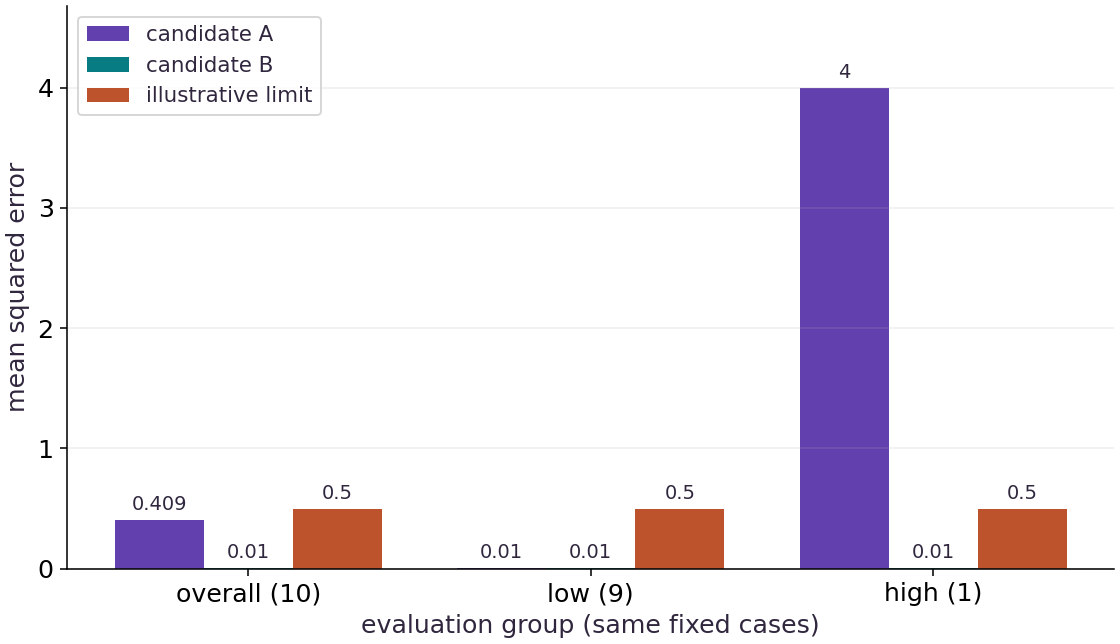

In [3]:
# Render the figure from the data computed above. Change the data experiment and rerun.
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 13, 'axes.labelcolor': '#30273e', 'text.color': '#30273e'})
def draw_panel(ax, data):
    import numpy as np
    palette = ['#6240ad', '#087c83', '#bc532c', '#405d9d']
    kind = data['kind']
    if kind in ('heatmap', 'field'):
        a = np.asarray(data['values'], dtype=float)
        assert a.ndim == 2 and np.isfinite(a).all()
        kw = {'cmap': 'PuOr' if data.get('diverging') else 'Purples', 'aspect': 'auto'}
        if kind == 'field':
            kw.update(extent=data['extent'], origin='lower', vmin=0, vmax=1)
        elif data.get('diverging'):
            limit = max(float(np.abs(a).max()), 1e-10)
            kw.update(vmin=-limit, vmax=limit)
        if data.get('scale') == 'probability' or data['unit'] in ('attention weight', 'next-token probability', 'masked-token probability'):
            kw.update(vmin=0, vmax=1)
        categorical = data.get('scale') == 'categorical' or any(name in data['unit'] for name in ('device ID','program ID'))
        if categorical:
            from matplotlib.colors import ListedColormap, BoundaryNorm
            from matplotlib import colormaps
            ids=np.unique(a).astype(int)
            boundaries=np.r_[ids[0]-.5,(ids[:-1]+ids[1:])/2,ids[-1]+.5]
            kw.update(cmap=ListedColormap([colormaps['tab20'](i) for i in range(len(ids))]), norm=BoundaryNorm(boundaries,len(ids)))
        im = ax.imshow(a, **kw)
        ax.figure.colorbar(im, ax=ax, shrink=0.8, label=data['unit'], **({'ticks':ids} if categorical else {}))
        if kind == 'heatmap':
            if a.size <= 32:
                mid = (float(a.min()) + float(a.max())) / 2
                for (i, j), value in np.ndenumerate(a):
                    rgb=im.cmap(im.norm(value))[:3]
                    luminance=sum(c*w for c,w in zip(rgb,[0.2126,0.7152,0.0722]))
                    ax.text(j, i, f'{value:.3g}', ha='center', va='center', fontsize=11,
                            color='white' if luminance < 0.5 else '#20202c')
            ax.set_xticks(range(a.shape[1]), data.get('columns', [str(i) for i in range(a.shape[1])]))
            ax.set_yticks(range(a.shape[0]), data.get('rows', [str(i) for i in range(a.shape[0])]))
            if a.shape[1] > 5: ax.tick_params(axis='x', labelsize=11)
        else:
            pts = np.asarray(data['points']); labels = np.asarray(data['labels'])
            for label, marker in [(0, 'o'), (1, '^')]:
                selected = pts[labels == label]
                ax.scatter(selected[:, 0], selected[:, 1], label=f'observed label {label}', marker=marker,
                           s=38, facecolors='white' if label == 0 else '#f4b547', edgecolors='#272238', linewidths=1)
            ax.legend(loc='upper left', fontsize=10)
    elif kind in ('line', 'bar'):
        series = data['series']
        x = np.asarray(data.get('x', list(range(len(data.get('labels', []))))))
        assert len(x) and np.isfinite(x).all()
        for i, s in enumerate(series):
            y = np.asarray(s['y'], dtype=float)
            assert y.shape == x.shape and np.isfinite(y).all(), s['label']
            if data.get('yscale') == 'log': assert (y > 0).all()
            if kind == 'line':
                ax.plot(x, y, color=palette[i % len(palette)], label=s['label'], linewidth=2.3,
                        linestyle=['-', '--', '-.', ':'][i % 4], marker='o' if len(x) <= 25 else None, markersize=3)
            else:
                width = 0.78 / len(series)
                bars = ax.bar(x + (i - (len(series)-1)/2)*width, y, width, label=s['label'], color=palette[i % len(palette)])
                if len(x)*len(series) <= 12: ax.bar_label(bars, fmt='%.3g', fontsize=10, padding=3)
        if kind == 'bar':
            ax.set_xticks(x, data['labels'])
            ax.margins(y=0.17)
            if any(len(t) > 13 for t in data['labels']): ax.tick_params(axis='x', labelrotation=15, labelsize=11)
        if data.get('xscale'): ax.set_xscale(data['xscale'])
        if data.get('yscale'): ax.set_yscale(data['yscale'], **({'linthresh':data.get('linthresh',2)} if data['yscale']=='symlog' else {}))
        for marker in data.get('markers',[]):
            ax.scatter([marker['x']],[marker['y']],color='#bc532c',s=45,zorder=5)
            ax.annotate(marker['label'],(marker['x'],marker['y']),xytext=(-85,12),textcoords='offset points',fontsize=10)
        for boundary in data.get('boundaries', []): ax.axvline(boundary, color='#716e7b', linestyle=':', linewidth=1)
        ax.grid(axis='y', alpha=0.2)
        ax.legend(fontsize=11, loc='best')
    elif kind == 'table':
        headers = data['headers']
        rows = data['rows']
        assert headers and rows and all(len(row) == len(headers) for row in rows)
        ax.axis('off')
        table = ax.table(cellText=rows, colLabels=headers, cellLoc='center',
                         loc='center', colWidths=data.get('widths'))
        table.auto_set_font_size(False)
        table.set_fontsize(11)
        table.scale(1, 2.7)
        for (row, _), cell in table.get_celld().items():
            cell.set_edgecolor('#ccd3df')
            cell.set_facecolor('#e9e4f5' if row == 0 else ('#f4f7fb' if row % 2 else '#ffffff'))
            cell.set_text_props(color='#172334', weight='bold' if row == 0 else 'normal')
    elif kind == 'vectors':
        for i, arrow in enumerate(data['arrows']):
            start = np.asarray(arrow['start']); end = np.asarray(arrow['end'])
            ax.annotate('', xy=end, xytext=start, arrowprops={'arrowstyle':'->','color':palette[i], 'lw':2.8})
            mid=(start+end)/2
            ax.annotate(arrow['label'], mid, xytext=(7,7), textcoords='offset points', color=palette[i])
        ax.set(xlim=(-0.7,4.5),ylim=(-0.7,5),xlabel='first coordinate',ylabel='second coordinate')
        ax.set_aspect('equal'); ax.grid(alpha=0.2)
    elif kind == 'flow':
        from matplotlib.patches import FancyBboxPatch
        nodes=data['nodes']; ax.set(xlim=(0,1),ylim=(0,len(nodes))); ax.axis('off')
        if data.get('layout') == 'merge':
            import textwrap
            for i,label in enumerate(nodes[:3]):
                x=0.02+i*0.33
                ax.add_patch(FancyBboxPatch((x,3.7),0.29,1.0,boxstyle='round,pad=0.015',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(x+0.145,4.2,textwrap.fill(label,20),ha='center',va='center',fontsize=11)
                ax.annotate('',(0.5,2.8),(x+0.145,3.67),arrowprops={'arrowstyle':'->','color':'#6240ad'})
            for y,label in [(2.4,nodes[3]),(0.9,nodes[4])]:
                ax.add_patch(FancyBboxPatch((0.08,y-0.35),0.84,0.7,boxstyle='round,pad=0.025',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(0.5,y,label,ha='center',va='center',fontsize=12)
            ax.annotate('',(0.5,1.3),(0.5,2.0),arrowprops={'arrowstyle':'->','color':'#6240ad'})
        else:
            for i, label in enumerate(nodes):
                y=len(nodes)-i-0.5
                ax.add_patch(FancyBboxPatch((0.08,y-0.3),0.84,0.6,boxstyle='round,pad=0.025',facecolor='#f0eafa',edgecolor='#6240ad'))
                ax.text(0.5,y,label,ha='center',va='center',fontsize=12)
                if i<len(nodes)-1: ax.annotate('',(0.5,y-0.67),(0.5,y-0.32),arrowprops={'arrowstyle':'->','color':'#6240ad'})
    else: raise ValueError(f'Unknown figure kind: {kind}')
    if data.get('xlabel'): ax.set_xlabel(data['xlabel'])
    if data.get('ylabel'): ax.set_ylabel(data['ylabel'])
    if data.get('title'): ax.set_title(data['title'], loc='left', fontsize=12, pad=12)
    for spine in ('top','right'): ax.spines[spine].set_visible(False)


def draw_mechanism(ax, diagram):
    """Draw a source-authored conceptual/analytic mechanism, never measured data."""
    import numpy as np
    from matplotlib.patches import FancyBboxPatch, Rectangle, Circle, Ellipse
    panel = diagram['panel']
    kind = panel['kind']
    colors = {'data':('#eef3ff','#3559a8'), 'state':('#f0eafa','#6240ad'),
              'fixed':('#f1f3f5','#536273'), 'result':('#e5f4ee','#17735c'),
              'warning':('#fff0e6','#a64d20')}
    if kind == 'graph':
        ax.set(xlim=(0,panel.get('width',10)),ylim=(panel.get('height',8),0))
        ax.axis('off')
        nodes={node['id']:node for node in panel['nodes']}
        for edge in panel['edges']:
            a,b=nodes[edge['from']],nodes[edge['to']]
            side_a=edge.get('exit','bottom'); side_b=edge.get('enter','top')
            def port(node,side):
                x,y=node['x'],node['y']; w,h=node.get('w',3),node.get('h',.8)
                return {'top':(x,y-h/2),'bottom':(x,y+h/2),'left':(x-w/2,y),'right':(x+w/2,y)}[side]
            start,end=port(a,side_a),port(b,side_b)
            ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'-|>','color':'#536273','lw':1.7,'connectionstyle':edge.get('curve','arc3,rad=0')},zorder=1)
            if edge.get('label'):
                tx,ty=edge.get('labelAt',((start[0]+end[0])/2,(start[1]+end[1])/2))
                ax.text(tx,ty,edge['label'],ha='center',va='center',fontsize=10,color='#394658',bbox={'facecolor':'white','edgecolor':'none','pad':2},zorder=4)
        for node in panel['nodes']:
            fill,stroke=colors[node.get('tone','data')]
            x,y=node['x'],node['y'];w,h=node.get('w',3),node.get('h',.8)
            ax.add_patch(FancyBboxPatch((x-w/2,y-h/2),w,h,boxstyle='round,pad=0.02,rounding_size=0.07',facecolor=fill,edgecolor=stroke,lw=1.5,zorder=2))
            ax.text(x,y,node['label'],ha='center',va='center',fontsize=node.get('fontSize',12),color='#172334',zorder=3)
    elif kind == 'table':
        ax.axis('off')
        table=ax.table(cellText=panel['rows'],colLabels=panel['headers'],cellLoc='center',loc='center',colWidths=panel.get('widths'))
        table.auto_set_font_size(False);table.set_fontsize(12);table.scale(1,2.7)
        for (row,col),cell in table.get_celld().items():
            cell.set_edgecolor('#ccd3df')
            cell.set_facecolor('#e9e4f5' if row==0 else ('#f4f7fb' if row%2 else '#ffffff'))
            cell.set_text_props(color='#172334',weight='bold' if row==0 else 'normal')
    elif kind == 'clipping':
        ax.add_patch(Circle((0,0),2.5,fill=False,edgecolor='#17735c',linestyle='--',lw=1.8))
        ax.add_patch(Rectangle((-2.5,-2.5),5,5,fill=False,edgecolor='#a64d20',linestyle=':',lw=1.8))
        for end,color,label,offset in [((3,4),'#3559a8','Original (3, 4)',(8,5)),((1.5,2),'#17735c','Norm clip (1.5, 2)',(-126,-16)),((2.5,2.5),'#a64d20','Coordinate clip (2.5, 2.5)',(8,-2))]:
            ax.annotate('',xy=end,xytext=(0,0),arrowprops={'arrowstyle':'-|>','color':color,'lw':2.6})
            ax.annotate(label,end,xytext=offset,textcoords='offset points',color=color,fontsize=11)
        ax.set(xlim=(-3,5.8),ylim=(-3,4.8),xlabel='gradient coordinate 1',ylabel='gradient coordinate 2')
        ax.set_aspect('equal');ax.grid(alpha=.15)
    elif kind == 'patches':
        ax.set(xlim=(-.1,4.1),ylim=(4.1,-.1));ax.set_aspect('equal');ax.axis('off')
        for i in range(4):
            x,y=(i%2)*2,(i//2)*2
            visible=i in [0,3]
            ax.add_patch(Rectangle((x,y),2,2,facecolor='#e5f4ee' if visible else '#fff0e6',edgecolor='#17735c' if visible else '#a64d20',hatch=None if visible else '///',lw=2))
            ax.text(x+1,y+1,f'Patch {i}\n'+('visible input' if visible else 'hidden target'),ha='center',va='center',fontsize=14,bbox={'facecolor':'white','edgecolor':'none','alpha':.94,'pad':5})
        for a in [1,3]:
            ax.axhline(a,color='#172334',alpha=.25,lw=.7);ax.axvline(a,color='#172334',alpha=.25,lw=.7)
    elif kind == 'receptive-field':
        ax.set(xlim=(-.15,5.15),ylim=(5.15,-.15));ax.set_aspect('equal');ax.axis('off')
        for row in range(5):
            for col in range(5):
                selected=1<=row<=3 and 1<=col<=3
                ax.add_patch(Rectangle((col,row),1,1,facecolor='#e9e4f5' if selected else '#f4f7fb',edgecolor='#a6afc1',lw=1))
                ax.text(col+.5,row+.5,f'{row},{col}',ha='center',va='center',fontsize=12)
        ax.add_patch(Rectangle((1,1),3,3,fill=False,edgecolor='#6240ad',lw=3))
        ax.set_title('One 3 × 3 receptive field inside a 5 × 5 input',fontsize=13,pad=12)
    elif kind == 'covariance':
        for covariance,color,label in [(np.array([[1,.8],[.8,1]]),'#6240ad','Correlated covariance'),(np.eye(2),'#17735c','Same marginals, zero covariance')]:
            eig,vec=np.linalg.eigh(covariance);order=np.argsort(eig)[::-1];eig=eig[order];vec=vec[:,order]
            angle=np.degrees(np.arctan2(vec[1,0],vec[0,0]))
            ax.add_patch(Ellipse((0,0),2*np.sqrt(eig[0]),2*np.sqrt(eig[1]),angle=angle,fill=False,lw=2.5,edgecolor=color,label=label))
        ax.set(xlim=(-1.8,1.8),ylim=(-1.8,1.8),xlabel='first variable',ylabel='second variable')
        ax.set_aspect('equal');ax.grid(alpha=.2);ax.legend(loc='upper center',bbox_to_anchor=(.5,-.14),fontsize=10)
    elif kind == 'timeline':
        ax.set(xlim=(0,10),ylim=(-.7,2.7),yticks=[0,1,2],yticklabels=['Host','Device','Measurement'])
        for start,length,y,label,color in [(0,1,0,'dispatch','#3559a8'),(1,6,1,'device work','#6240ad'),(1,6,0,'wait for result','#a64d20'),(0,7,2,'completed-result interval','#17735c')]:
            ax.barh(y,length,left=start,height=.45,color=color,alpha=.18)
            ax.text(start+length/2,y,label,ha='center',va='center',fontsize=11)
        ax.axvline(7,color='#536273',linestyle='--');ax.text(7.1,.5,'result ready',fontsize=11)
        ax.set_xlabel('conceptual order; lengths are not measured durations')
        ax.invert_yaxis()
    else:
        raise ValueError(f'Unknown mechanism kind: {kind}')

panels = visual_data.get('panels', [visual_data])
fig, axes = plt.subplots(len(panels), 1, figsize=(8, 4.6 * len(panels)), squeeze=False, layout='constrained')
for ax, panel in zip(axes[:, 0], panels):
    draw_panel(ax, panel)
plt.show()

### Read the figure

On the same $10$ held-out rows, candidate A has overall MSE $0.409$, low-slice MSE $0.01$ across $9$ rows, and high-slice MSE $4.0$ on $1$ row. Candidate B has MSE $0.01$ in all three groups. The dashed $0.5$ line is the illustrative limit: A's overall bar sits below it, but its high-slice bar exceeds it; B clears every gate. The denominator printed in each label tells you how many rows support that bar.

### Connect it to the computation

Each bar is calculated from squared prediction errors after the named artifact is reloaded. The paired run holds case IDs, targets, splits, slice counts and the $0.5$ policy fixed while changing candidate B's high-slice offset. The separate label-correction check holds candidate A fixed and changes one target, so it is not a third candidate comparison.

## Tighten one shared release policy without changing either model

Predict: Candidate A has high-slice MSE $4$, while B has MSE $0.01$. With the same ten cases and a shared limit of $0.005$, should either model pass? Compare that decision with the original $0.5$ limit.

In [4]:
# Change only the shared policy; preserve both serialized artifacts and evaluation rows.
with tempfile.TemporaryDirectory(prefix='mlops-policy-change-') as folder:
    policy_root=Path(folder)
    policy_results={}
    for name,saved_model in [('A',artifact),('B',candidate_b)]:
        model_path=policy_root/(name+'.json')
        model_path.write_text(json.dumps(saved_model,sort_keys=True))
        fixed_cases,strict_metrics,_=evaluate_reloaded(rows,model_path,.005)
        _,original_metrics,_=evaluate_reloaded(rows,model_path,.5)
        assert [(r['id'],r['target'],r['slice']) for r in fixed_cases]==[(r['id'],r['target'],r['slice']) for r in per]
        assert strict_metrics['overall']['count']==original_metrics['overall']['count']==10
        assert strict_metrics['low']==original_metrics['low']
        assert strict_metrics['high']==original_metrics['high']
        assert not strict_metrics['passed']
        policy_results[name]={'original_pass':original_metrics['passed'],'strict_pass':strict_metrics['passed']}
    assert policy_results=={'A':{'original_pass':False,'strict_pass':False},'B':{'original_pass':True,'strict_pass':False}}
print('Same predictions, changed policy:',policy_results)


Same predictions, changed policy: {'A': {'original_pass': False, 'strict_pass': False}, 'B': {'original_pass': True, 'strict_pass': False}}


Expected: At the original limit, A fails and B passes. At the stricter shared limit, both fail, although neither model prediction nor case identity changed.

A release decision depends on a declared policy as well as observed errors. Tightening the threshold must not change the underlying metric values. Both candidates here are predefined synthetic teaching artifacts; the offset is not a claim of a learned improvement on an independent real task.

## Your exercise

Compare the two reloaded artifacts at the same ten held-out IDs and fixed policy. Change only candidate B’s high-slice offset from 1.9 to 0.5, then report its per-example high-slice error and gate result. Distinguish that candidate comparison from the separate label-correction sensitivity check.

### How to write this exercise — Step-by-step recipe & starter scaffold

**Inputs:**
- The two slice mean errors and their example counts.

**Outputs:**
- The unweighted mean of slice means and the count-weighted overall error for comparison.

**Invariants to check:**
- Unequal slice counts can make the unweighted average differ from the overall per-example mean.

**Hints:**
- Multiply each slice mean by its count to recover its error sum.
- Divide the combined sum by the combined count.

**Starter code scaffold (fill in the TODOs):**

```python
import numpy as np

def compare_slice_averages(slice_means, slice_counts):
    # TODO: Compute the simple mean of slice means and the count-weighted overall mean.
    raise NotImplementedError
```

In [5]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference solution

Try your own implementation first.

In [6]:
# This separate check changes one candidate parameter while freezing the labels.
changed_b=dict(artifact,slice_offsets={'high':.5})
with tempfile.TemporaryDirectory() as work:
    path=Path(work)/'changed-b.json'; path.write_text(json.dumps(changed_b))
    per_c,metrics_c,_=evaluate_reloaded(rows,path,.5)
assert [(v['id'],v['target'],v['slice']) for v in per_c]==[(v['id'],v['target'],v['slice']) for v in per]
assert math.isclose(metrics_c['high']['mse'],2.25,abs_tol=1e-12)
assert not metrics_c['passed']
high_example=next(v for v in per_c if v['slice']=='high')
assert math.isclose(high_example['squared_error'],2.25,abs_tol=1e-12)
print('candidate B high-slice example:',high_example)
print('candidate B with offset 0.5:',metrics_c)
print('Artifact A and B are distinct:',digest(artifact)!=digest(changed_b))

candidate B high-slice example: {'id': 'high-0', 'slice': 'high', 'target': 19.0, 'prediction': 17.5, 'squared_error': 2.25}
candidate B with offset 0.5: {'low': {'count': 9, 'mse': 0.009999999999999988}, 'high': {'count': 1, 'mse': 2.25}, 'overall': {'count': 10, 'mse': 0.23399999999999999}, 'passed': False}
Artifact A and B are distinct: True


## Change the population mix · transfer

Keep each slice’s measured error fixed, but evaluate nine high-slice examples and one low-slice example. Recompute the weighted overall MSE from errors produced by the reloaded artifact.

Hint: Change counts rather than the model errors.

### How to write: Change the population mix — Step-by-step recipe & starter scaffold

**Inputs:**
- Keep the two slice errors, but evaluate nine high-slice examples and one low-slice example.

**Outputs:**
- A weighted overall error under the new slice counts.

**Invariants to check:**
- Slice errors remain fixed while only population counts change.

**Hints:**
- Change counts rather than the model errors.
- Weight slice errors by their example counts.

**Starter code scaffold (fill in the TODOs):**

```python
import math

def practice_change_the_population_mix(high_error, low_error, high_count, low_count):
    """Complete the change the population mix check."""
    # TODO: ('Keep high/low slice errors fixed and recompute weighted aggregate error for nine high-slice and one low-slice example.', 'New count-weighted aggregate error and unchanged slice metrics.', 'Weights come from the new example counts, not an unweighted mean of slice means.')
    raise NotImplementedError
```

In [7]:
# Write your attempt here (uncomment and fill in the TODOs below):


## Reference reasoning

Aggregate performance changes with population mix even when each slice’s error is unchanged. Report both before attributing the change to a model regression.

In [8]:
# `metrics` was computed from per-example errors after loading the local artifact.
low_mse=metrics['low']['mse']; high_mse=metrics['high']['mse']
new_low_count=1; new_high_count=9
weighted=(new_low_count*low_mse+new_high_count*high_mse)/(new_low_count+new_high_count)
assert math.isclose(weighted,3.601)
assert low_mse==metrics['low']['mse'] and high_mse==metrics['high']['mse']
print('new weighted MSE:',weighted,'unchanged slice MSEs:',low_mse,high_mse)

new weighted MSE: 3.601 unchanged slice MSEs: 0.009999999999999988 4.0


## Checkpoint

An input drift alert fired before new labels arrived. What follows?

1. Retrain and automatically replace the active model.
2. Investigate the change and gather quality evidence before choosing a response.
3. Declare accuracy has decreased by the drift score.

## Diagnose

Check denominators and slice counts before thresholds. A missing slice, nonfinite metric or changed evaluation manifest should block comparison. Investigate drift and training-serving skew separately from service health.

## Evidence

Keep reloaded predictions, target/case identities, per-example and slice metrics, independent weighted aggregation and an explicit release decision with leakage and drift caveats.

<details><summary>Compare checkpoint reasoning after your attempt</summary>

**1. Retrain and automatically replace the active model.**

Drift can reflect harmless distribution changes or instrumentation faults. Investigate data and labeled quality before promotion.

**2. Investigate the change and gather quality evidence before choosing a response. (correct)**

An unlabeled drift alert is evidence of a distribution change under the detector, not direct evidence of accuracy loss. Investigate data integrity, affected slices, service health and delayed outcomes. Retraining and promotion require their own declared quality gates.

**3. Declare accuracy has decreased by the drift score.**

Input drift and accuracy loss are different observations. Without labels, the detector cannot directly measure accuracy.

</details>

## Carry forward

- Validate data before the expensive job
- Compare distributions without inventing labels
- Rehearse the failed gate

## Primary references

- [Google Cloud MLOps: continuous delivery and automation](https://cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning)
- [MLflow experiment tracking](https://mlflow.org/docs/latest/ml/tracking/quickstart/)
- [MLflow model registry workflows](https://mlflow.org/docs/latest/ml/model-registry/workflow/)